In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

SOLAR = "../data/raw/solar"
for f in os.listdir(SOLAR):
    print(f, round(os.path.getsize(os.path.join(SOLAR, f)) / 1e6, 2), "MB")

Plant_1_Generation_Data.csv 4.84 MB
Plant_1_Weather_Sensor_Data.csv 0.29 MB
Plant_2_Generation_Data.csv 5.81 MB
Plant_2_Weather_Sensor_Data.csv 0.3 MB


In [2]:
files = {
    "p1_gen": "Plant_1_Generation_Data.csv",
    "p1_wx": "Plant_1_Weather_Sensor_Data.csv",
    "p2_gen": "Plant_2_Generation_Data.csv",
    "p2_wx": "Plant_2_Weather_Sensor_Data.csv",
}
dfs = {k: pd.read_csv(os.path.join(SOLAR, v)) for k, v in files.items()}

for k, df in dfs.items():
    print("=" * 60)
    print(k, df.shape)
    print(df.dtypes)
    print("missing:\n", df.isna().sum())
    print("duplicates:", df.duplicated().sum())
    display(df.head(3))

p1_gen (68778, 7)
DATE_TIME          str
PLANT_ID         int64
SOURCE_KEY         str
DC_POWER       float64
AC_POWER       float64
DAILY_YIELD    float64
TOTAL_YIELD    float64
dtype: object
missing:
 DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64
duplicates: 0


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0


p1_wx (3182, 6)
DATE_TIME                  str
PLANT_ID                 int64
SOURCE_KEY                 str
AMBIENT_TEMPERATURE    float64
MODULE_TEMPERATURE     float64
IRRADIATION            float64
dtype: object
missing:
 DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64
duplicates: 0


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0


p2_gen (67698, 7)
DATE_TIME          str
PLANT_ID         int64
SOURCE_KEY         str
DC_POWER       float64
AC_POWER       float64
DAILY_YIELD    float64
TOTAL_YIELD    float64
dtype: object
missing:
 DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64
duplicates: 0


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15 00:00:00,4136001,4UPUqMRk7TRMgml,0.0,0.0,9425.000000,2.429011e+06
1,2020-05-15 00:00:00,4136001,81aHJ1q11NBPMrL,0.0,0.0,0.000000,1.215279e+09
2,2020-05-15 00:00:00,4136001,9kRcWv60rDACzjR,0.0,0.0,3075.333333,2.247720e+09


p2_wx (3259, 6)
DATE_TIME                  str
PLANT_ID                 int64
SOURCE_KEY                 str
AMBIENT_TEMPERATURE    float64
MODULE_TEMPERATURE     float64
IRRADIATION            float64
dtype: object
missing:
 DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64
duplicates: 0


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4136001,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0
1,2020-05-15 00:15:00,4136001,iq8k7ZNt4Mwm3w0,26.880811,24.421869,0.0
2,2020-05-15 00:30:00,4136001,iq8k7ZNt4Mwm3w0,26.682055,24.427290,0.0


In [3]:
# Plant 1 generation uses day-first dates (DD-MM-YYYY); the others don't
dfs["p1_gen"]["DATE_TIME"] = pd.to_datetime(dfs["p1_gen"]["DATE_TIME"], dayfirst=True)
for k in ["p1_wx", "p2_gen", "p2_wx"]:
    dfs[k]["DATE_TIME"] = pd.to_datetime(dfs[k]["DATE_TIME"])

for k, df in dfs.items():
    print(k, df["DATE_TIME"].min(), "->", df["DATE_TIME"].max(),
          "| unique timestamps:", df["DATE_TIME"].nunique())

for k in ["p1_gen", "p2_gen"]:
    print(k, "inverters:", dfs[k]["SOURCE_KEY"].nunique())

p1_gen 2020-05-15 00:00:00 -> 2020-06-17 23:45:00 | unique timestamps: 3158
p1_wx 2020-05-15 00:00:00 -> 2020-06-17 23:45:00 | unique timestamps: 3182
p2_gen 2020-05-15 00:00:00 -> 2020-06-17 23:45:00 | unique timestamps: 3259
p2_wx 2020-05-15 00:00:00 -> 2020-06-17 23:45:00 | unique timestamps: 3259
p1_gen inverters: 22
p2_gen inverters: 22


In [4]:
for k in ["p1_gen", "p2_gen"]:
    df = dfs[k]
    per_inv = df.groupby("SOURCE_KEY").size()
    print(k, "rows per inverter: min", per_inv.min(), "max", per_inv.max())
    night = df[df["DATE_TIME"].dt.hour.isin([0, 1, 2, 3, 22, 23])]
    print(k, "mean AC at night:", night["AC_POWER"].mean())

# Expected 15-min timestamps vs actual in plant 1 weather
full = pd.date_range(dfs["p1_wx"]["DATE_TIME"].min(),
                     dfs["p1_wx"]["DATE_TIME"].max(), freq="15min")
print("plant 1 weather missing intervals:", len(full) - dfs["p1_wx"]["DATE_TIME"].nunique())

p1_gen rows per inverter: min 3104 max 3155
p1_gen mean AC at night: 0.0
p2_gen rows per inverter: min 2355 max 3259
p2_gen mean AC at night: 0.0
plant 1 weather missing intervals: 82


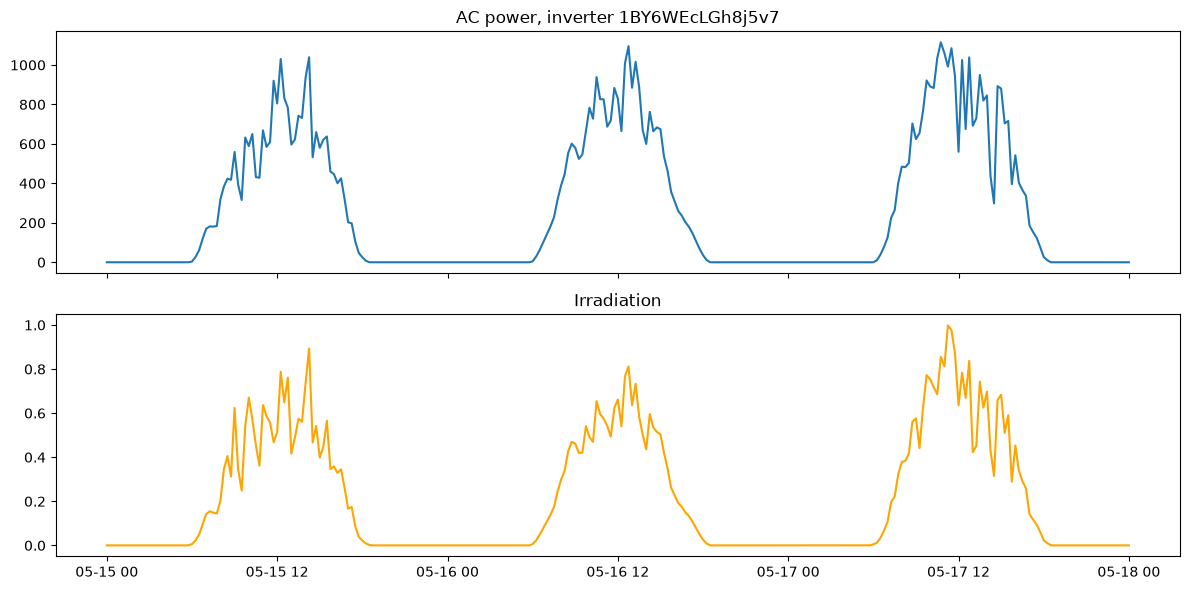

In [5]:
g = dfs["p1_gen"]
inv = g["SOURCE_KEY"].iloc[0]
start = g["DATE_TIME"].min().normalize()
end = start + pd.Timedelta(days=3)

a = g[(g["SOURCE_KEY"] == inv) & g["DATE_TIME"].between(start, end)]
w = dfs["p1_wx"][dfs["p1_wx"]["DATE_TIME"].between(start, end)]

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(a["DATE_TIME"], a["AC_POWER"]); ax[0].set_title(f"AC power, inverter {inv}")
ax[1].plot(w["DATE_TIME"], w["IRRADIATION"], color="orange"); ax[1].set_title("Irradiation")
plt.tight_layout(); plt.show()